# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Thomas Jeremy S. Gonzaga
- _Student No._: 2023-16222
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="problem1_FTvary.png" alt="Alt text" width=95%>

#### Report discussion
The Fourier Transform of a Gaussian waveform shows that inserve relationship of its time domain and frequency domain. If we increase the standard deviation the signal widens in the time domain meaning the spectrum compresses into a tall and narrow Gaussian peak in the frequency domain. If we decrease the standard deviation on the other hand the time domain pulse sharpens causing its frequency spectrum to spread out over a broader range.

<img src="problem2_noiserecover.png" alt="Alt text" width=95%>

#### Report discussion
Lowering $N$ will lower the total signal duration and resolution. This would cause broader FFT magnitudes and leakage which would make data recovery from noisy data harder as more features are lost. The lower limit of $N$ is determined by the Nyquist rate as to prevent aliasing and provide a sufficient window width.

<img src="problem3_aliasing.png" alt="Alt text" width=95%>

#### Report discussion
The figure demonstrates how sampling rate affects the sinusoidal signal. To satify the aformentioned Nyquist floor, the sampling frequency must go over the Nyquist Rate $f_s > 2 f_{\text{sig}} = 200\text{ Hz}$.

For a non-aliased signal, the sampling is well above the Nyquist rate and accuratley captures the oscillation in the time domain. For the aliased signal on the other hand, we observe undersampling below the Nyquist rate which causes frequency folding which can be observed in the time domain with its misrepresented sampling points.

### Other comments
- 学如逆水行舟，不进则退。

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

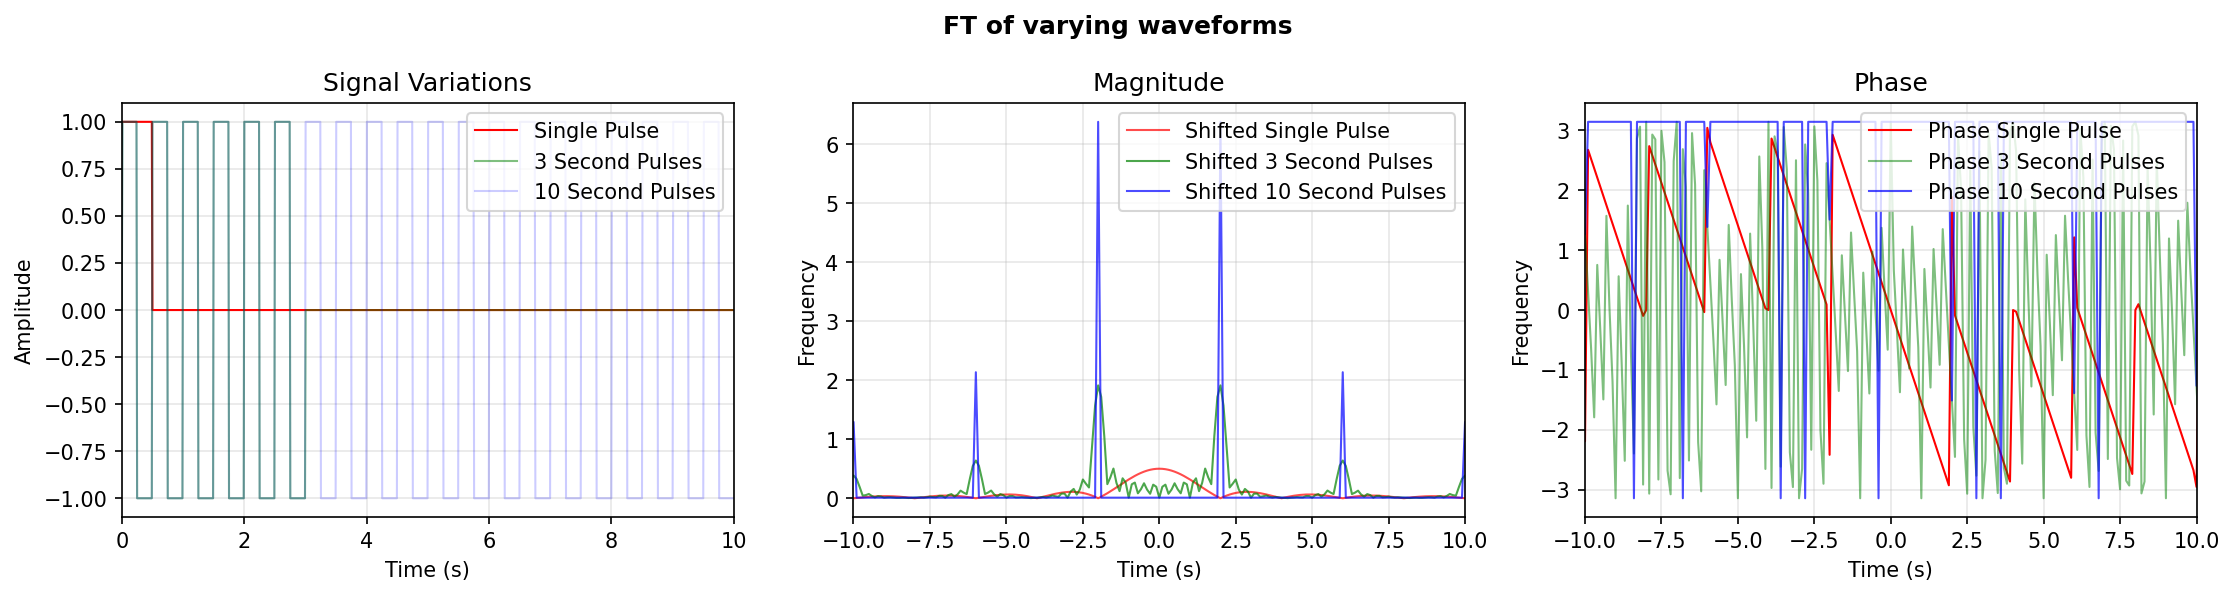

In [2]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
dt = t[1] - t[0]
f0 = 2 # frequency

# main signal, sinusoidal
square_full = np.sign(np.sin(2 * np.pi * f0 * t))

# pulse types
x1 = np.where(t <= 0.5, 1.0, 0.0) # one pulse
x2 = np.where(t <= 3.0, square_full, 0.0) # 3 seconds
x3 = np.where(t <= 10.0, square_full, 0.0) # 10 seconds

# shifted ffts, shifts zero-frequency to the center of the spectrum
x1_shifted = np.fft.fftshift(np.fft.fft(x1)*dt)
x2_shifted = np.fft.fftshift(np.fft.fft(x2)*dt)
x3_shifted = np.fft.fftshift(np.fft.fft(x3)*dt)

# frequency axis, calculated frequency values at each point
frequency_shifted = np.fft.fftshift(np.fft.fftfreq(len(t), d=dt))

# axis Plots

fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=150)
fig.suptitle('FT of varying waveforms', fontweight='bold')

# signal and variations
axes[0].plot(t, x1, label='Single Pulse', color='red', alpha=1, linewidth=1)
axes[0].plot(t, x2, label='3 Second Pulses', color='green', alpha=0.5, linewidth=1)
axes[0].plot(t, x3, label='10 Second Pulses', color='blue', alpha=0.2, linewidth=1)

# magnitudes
axes[1].plot(frequency_shifted, np.abs(x1_shifted), label='Shifted Single Pulse', color='red', alpha=0.7, linewidth=1)
axes[1].plot(frequency_shifted, np.abs(x2_shifted), label='Shifted 3 Second Pulses', color='green', alpha=0.7, linewidth=1)
axes[1].plot(frequency_shifted, np.abs(x3_shifted), label='Shifted 10 Second Pulses', color='blue', alpha=0.7, linewidth=1)

axes[2].plot(frequency_shifted, np.angle(x1_shifted), label='Phase Single Pulse', color='red', alpha=1, linewidth=1)
axes[2].plot(frequency_shifted, np.angle(x2_shifted), label='Phase 3 Second Pulses', color='green', alpha=0.5, linewidth=1)
axes[2].plot(frequency_shifted, np.angle(x3_shifted), label='Phase 10 Second Pulses', color='blue', alpha=0.7, linewidth=1)

axes[0].set_title('Signal Variations')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_xlim([0, 10])
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right')

axes[1].set_title('Magnitude')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Frequency')
axes[1].set_xlim([-10, 10])
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

axes[2].set_title('Phase')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Frequency')
axes[2].set_xlim([-10, 10])
axes[2].grid(True, alpha=0.3)
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.savefig("problem1_FTvary.png")
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [3]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 2500
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

freq_axis = np.fft.fftfreq(N, d=dt)

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

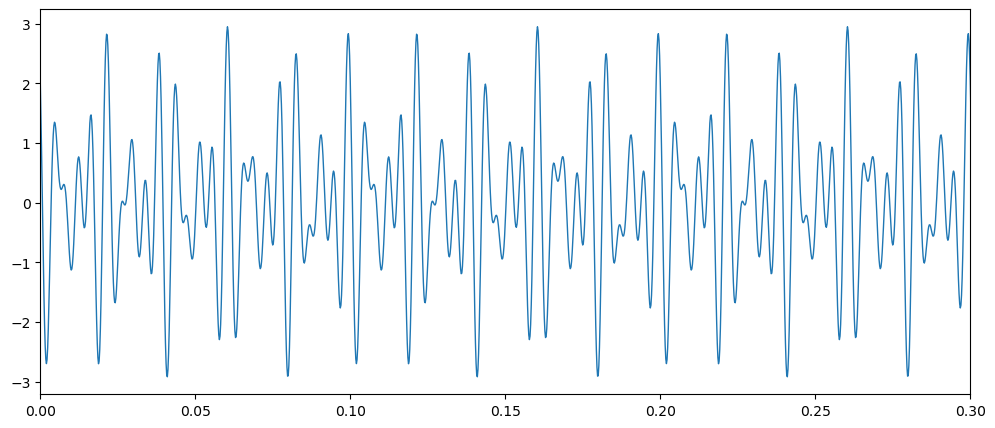

In [4]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original, linewidth=1)
ax.set_xlim(0,0.3)

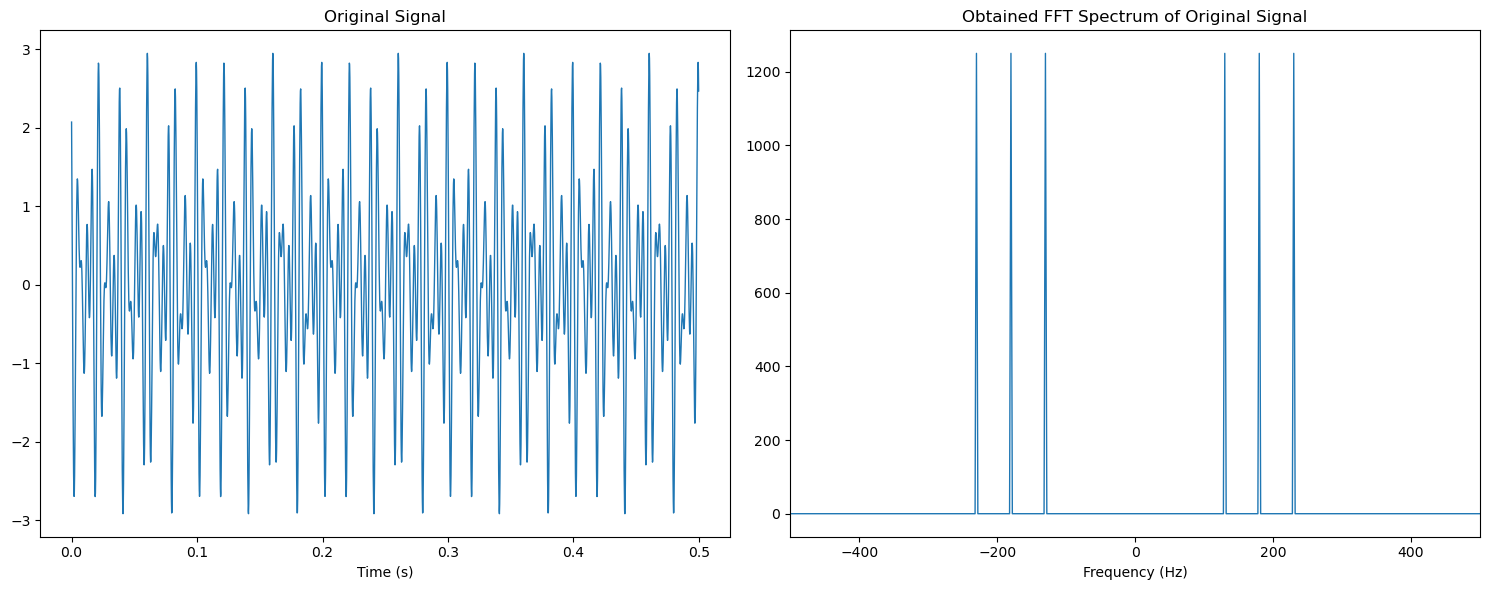

In [5]:
#FILL: Plot the fourier transform of the clean, original signal

# computes fft
fft_clean = np.fft.fft(signal_original)

# shift frequencies and compute absolute magnitude
freq_axis_shifted = np.fft.fftshift(freq_axis)
fft_magnitude = np.fft.fftshift(np.abs(fft_clean))

# plotting
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].plot(t_, signal_original, linewidth=1)
axes[0].set_title('Original Signal')
axes[0].set_xlabel('Time (s)')

axes[1].plot(freq_axis_shifted, fft_magnitude, linewidth=1)
axes[1].set_title('Obtained FFT Spectrum of Original Signal')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_xlim(-500, 500)

plt.tight_layout()
plt.show()

In [6]:
rng = np.random.default_rng(67)

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point

#Noisy data here
noisy_data5 = signal_original + noise*5
noisy_data1 = signal_original + noise

fft_clean_from_noise5 = np.fft.fft(noisy_data5)
fft_clean_from_noise1 = np.fft.fft(noisy_data1)

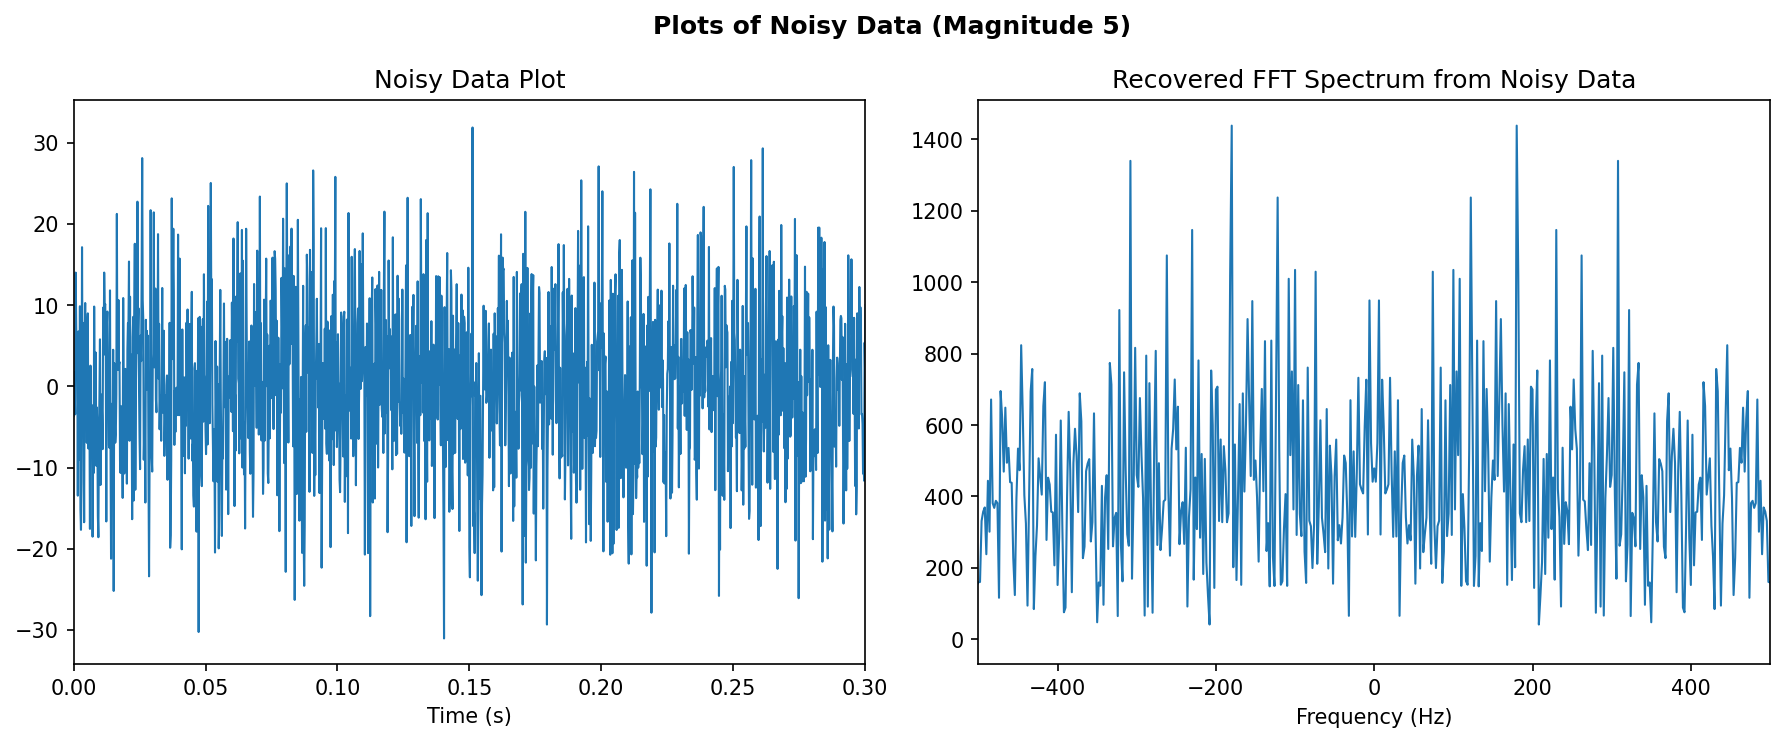

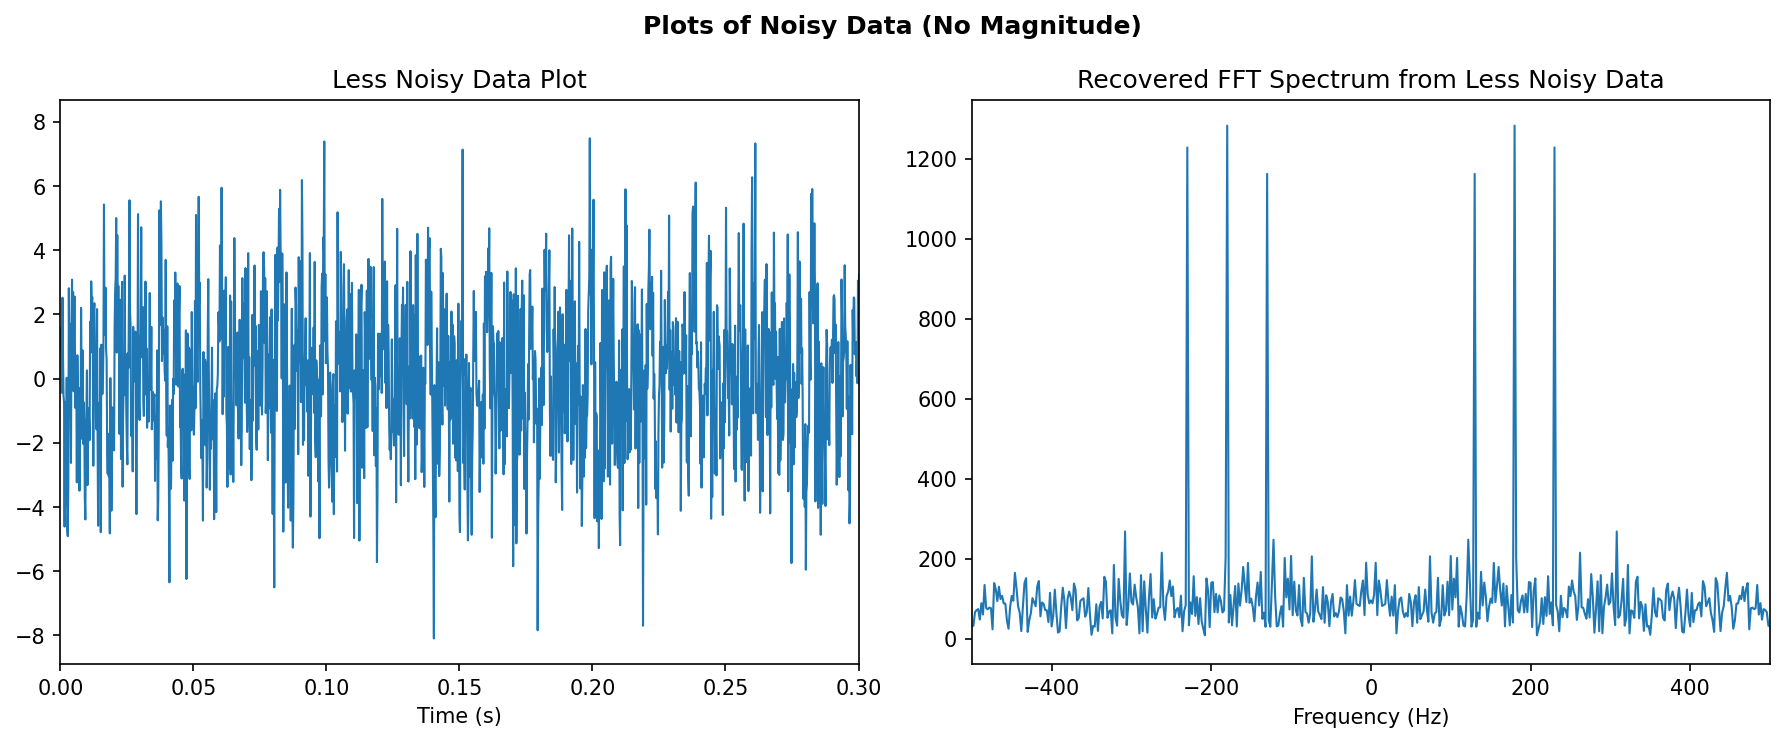

In [7]:
# compute magnitude and shift frequencies
freq_axis_shifted = np.fft.fftshift(freq_axis)

fft_mag_noise5 = np.fft.fftshift(np.abs(fft_clean_from_noise5))
fft_mag_noise1 = np.fft.fftshift(np.abs(fft_clean_from_noise1))

fig, axes = plt.subplots(1, 2, figsize= (12,5), dpi=150)
fig.suptitle('Plots of Noisy Data (Magnitude 5)', fontweight='bold')
axes[0].plot(t_, noisy_data5, linewidth=1)
axes[0].set_xlim(0,0.3)
axes[0].set_title('Noisy Data Plot')
axes[0].set_xlabel('Time (s)')

axes[1].plot(freq_axis_shifted, fft_mag_noise5, linewidth=1)
axes[1].set_title('Recovered FFT Spectrum from Noisy Data')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_xlim(-500, 500)

plt.tight_layout()
plt.show()

# Less Noise

fig, axes = plt.subplots(1, 2, figsize= (12,5), dpi=150)
fig.suptitle('Plots of Noisy Data (No Magnitude)', fontweight='bold')

axes[0].plot(t_, noisy_data1, linewidth=1)
axes[0].set_xlim(0,0.3)
axes[0].set_title('Less Noisy Data Plot')
axes[0].set_xlabel('Time (s)')

axes[1].plot(freq_axis_shifted, fft_mag_noise1, linewidth=1)
axes[1].set_title('Recovered FFT Spectrum from Less Noisy Data')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_xlim(-500, 500)

plt.tight_layout()
plt.show()

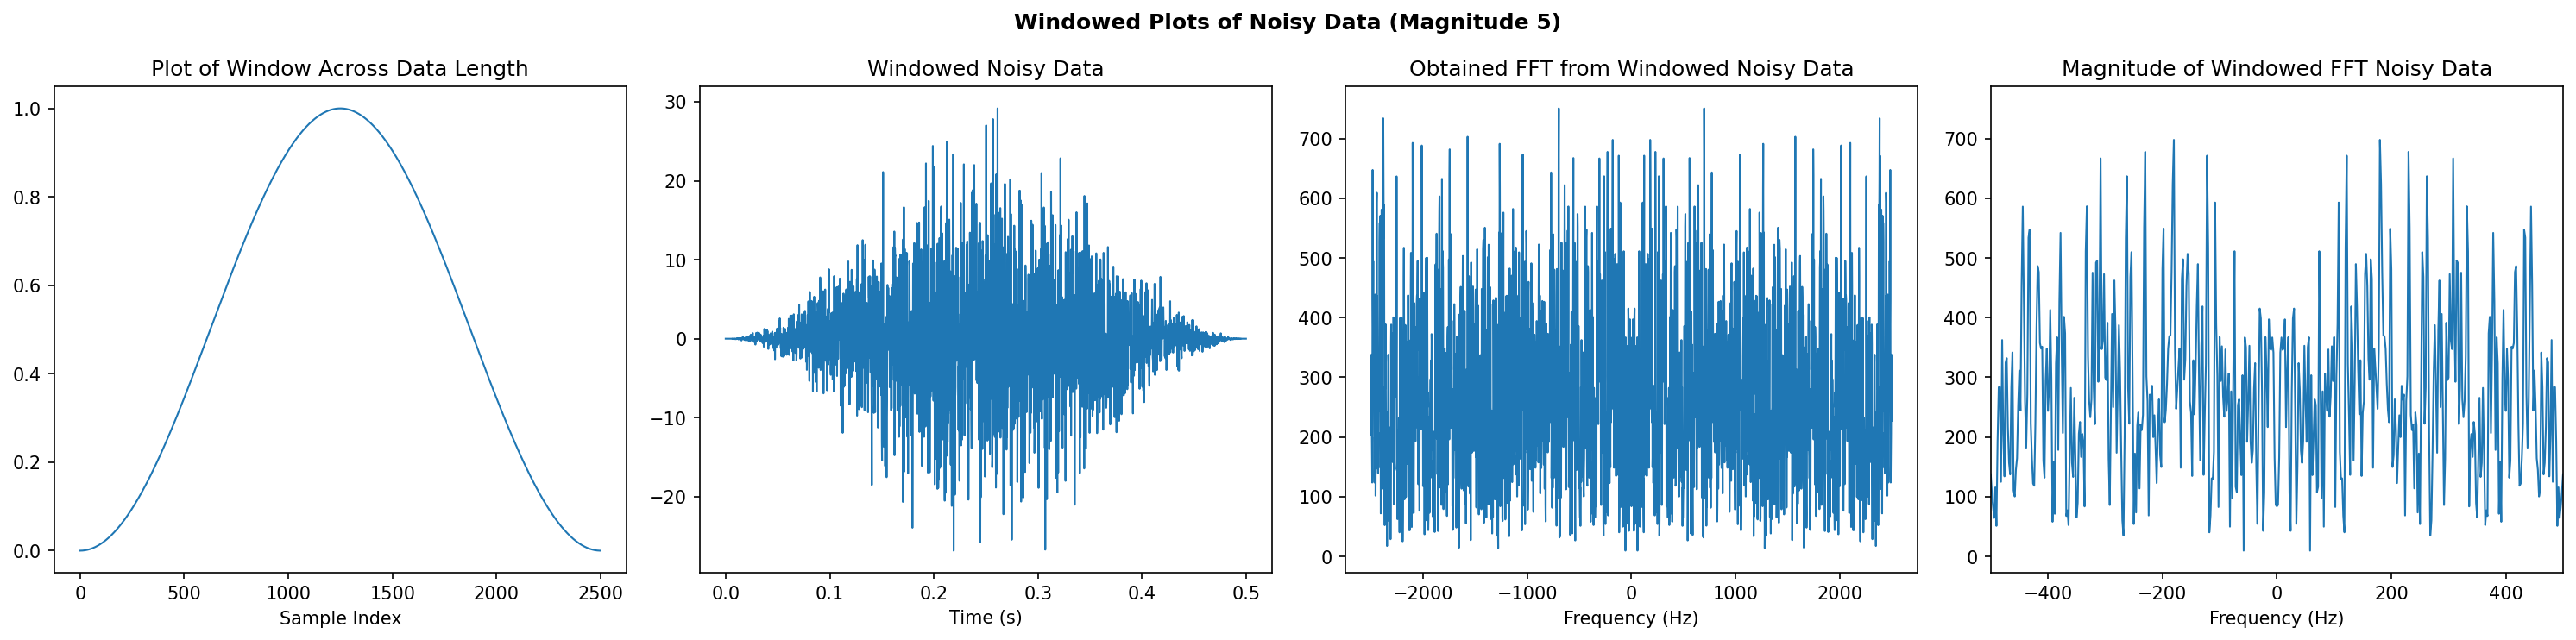

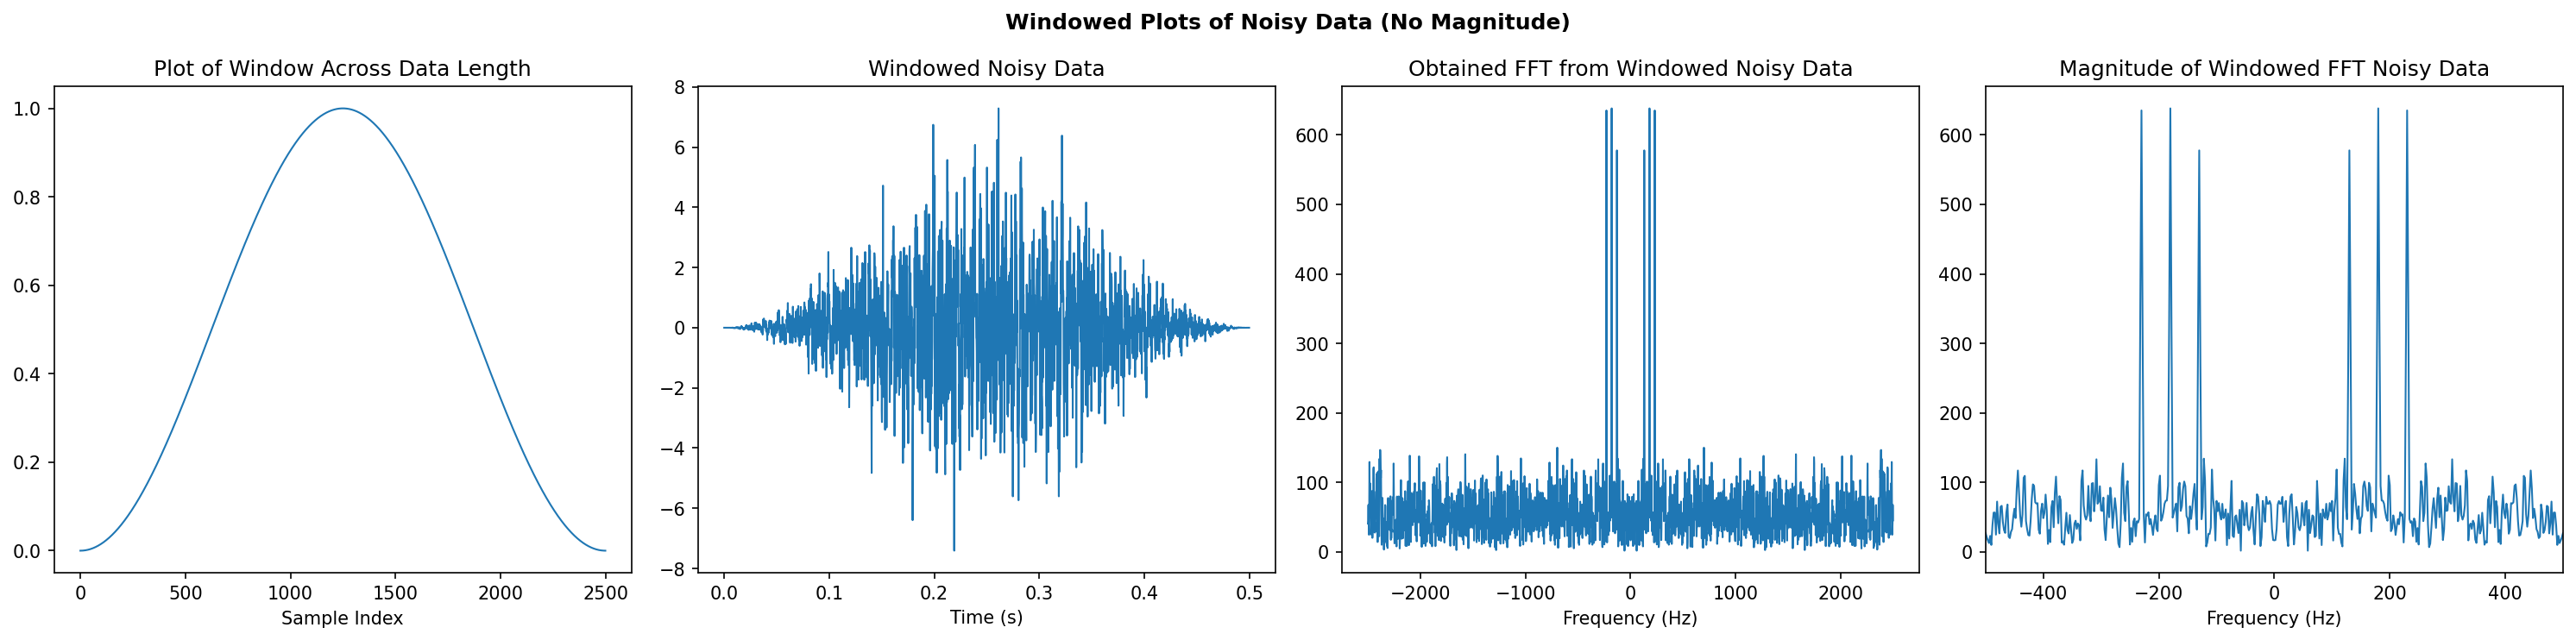

In [8]:
# 3.) Add a window (Hann)
window = np.hanning(len(noisy_data5)) #Create a window the size of the data length

noisy_data5_windowed = noisy_data5 * window
noisy_data1_windowed = noisy_data1 * window

# shifted for magnitude
freq_axis_shifted = np.fft.fftshift(freq_axis)

fft_win5_shifted = np.fft.fftshift(np.abs(np.fft.fft(noisy_data5_windowed)))
fft_win1_shifted = np.fft.fftshift(np.abs(np.fft.fft(noisy_data1_windowed)))

# plotting

fig, axes = plt.subplots(1, 4, figsize= (20,5), dpi=150)
fig.suptitle('Windowed Plots of Noisy Data (Magnitude 5)', fontweight='bold')
axes[0].plot(window, linewidth=1)
axes[0].set_title('Plot of Window Across Data Length')
axes[0].set_xlabel('Sample Index')

axes[1].plot(t_, noisy_data5_windowed, linewidth=1)
axes[1].set_title('Windowed Noisy Data')
axes[1].set_xlabel('Time (s)')

axes[2].plot(freq_axis_shifted, fft_win5_shifted, linewidth=1)
axes[2].set_title('Obtained FFT from Windowed Noisy Data')
axes[2].set_xlabel('Frequency (Hz)')

# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

axes[3].plot(freq_axis_shifted, fft_win5_shifted, linewidth=1)
axes[3].set_title('Magnitude of Windowed FFT Noisy Data')
axes[3].set_xlabel('Frequency (Hz)')
axes[3].set_xlim(-500, 500)

plt.tight_layout()
plt.show()

##### fig 2

fig, axes = plt.subplots(1, 4, figsize= (20,5), dpi=150)
fig.suptitle('Windowed Plots of Noisy Data (No Magnitude)', fontweight='bold')

axes[0].plot(window, linewidth=1)
axes[0].set_title('Plot of Window Across Data Length')
axes[0].set_xlabel('Sample Index')

axes[1].plot(t_, noisy_data1_windowed, linewidth=1)
axes[1].set_title('Windowed Noisy Data')
axes[1].set_xlabel('Time (s)')

axes[2].plot(freq_axis_shifted, fft_win1_shifted, linewidth=1)
axes[2].set_title('Obtained FFT from Windowed Noisy Data')
axes[2].set_xlabel('Frequency (Hz)')

# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

axes[3].plot(freq_axis_shifted, fft_win1_shifted, linewidth=1)
axes[3].set_title('Magnitude of Windowed FFT Noisy Data')
axes[3].set_xlabel('Frequency (Hz)')
axes[3].set_xlim(-500, 500)

plt.tight_layout()
plt.show()

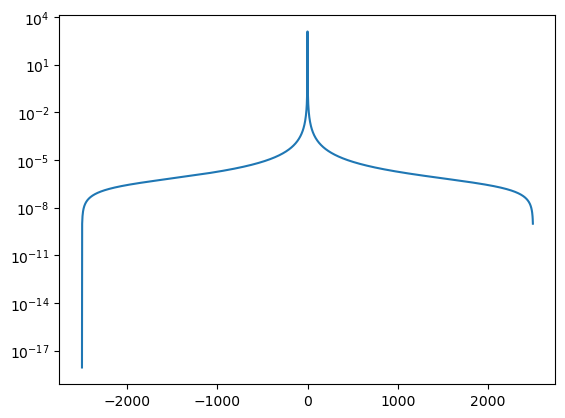

In [9]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [10]:
# noisyFourier = np.fft.fft(noisy_data5*window)
# noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data5*window)))

In [11]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
# 5.) Filter Below a Threshold

fft_raw = np.fft.fft(noisy_data5_windowed)
threshold = 550 # aboslute values nalang kasi i cant find the right fit
fft_filtered = np.where(np.abs(fft_raw) > threshold, fft_raw, 0) # keeps the fft values above the threshold and removes values under

In [12]:
# freq mask using bandpass filter
fft_raw = np.fft.fft(noisy_data5_windowed)
freqs_raw = np.fft.fftfreq(len(noisy_data5), dt)

# Create a boolean mask for the target frequencies (+/- 15 Hz band around each signal frequency)
target_freqs = [130, 180, 230]
mask = np.zeros(len(freqs_raw), dtype=bool)

for f in target_freqs:
    mask |= (np.abs(freqs_raw - f) < 15) | (np.abs(freqs_raw + f) < 15)

# Keep frequencies inside the bands, zero out everything else
fft_filtered = np.where(mask, fft_raw, 0)

In [13]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

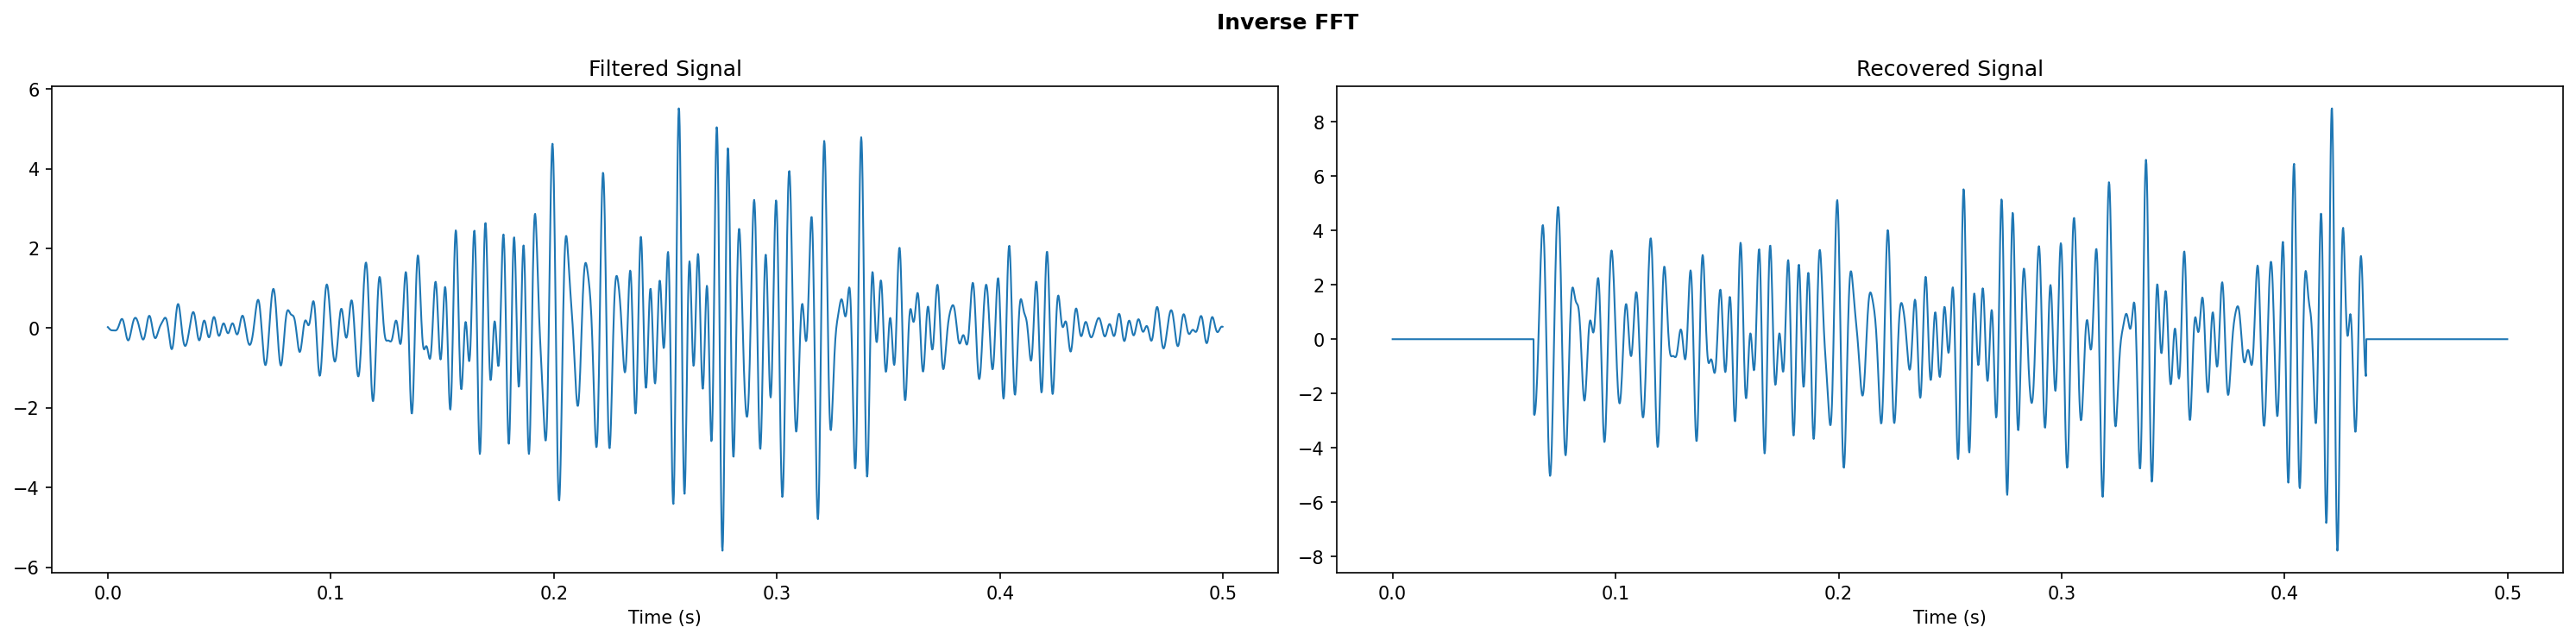

In [14]:
# 6.) get the inverse fft
signal_filtered = np.fft.ifft(fft_filtered).real

#safe threshold to avoid peaks at end
window_cutoff = 0.15
safe_window = np.where(window > window_cutoff, window, 1)

# divide when window is large enough
signal_recovered = np.where(window > window_cutoff, signal_filtered / safe_window, 0)

fig, axes = plt.subplots(1, 2, figsize=(20, 5), dpi=150)
fig.suptitle('Inverse FFT', fontweight='bold')

axes[0].plot(t_, signal_filtered, linewidth=1)
axes[0].set_title('Filtered Signal')
axes[0].set_xlabel('Time (s)')

axes[1].plot(t_, signal_recovered, linewidth=1)
axes[1].set_title('Recovered Signal')
axes[1].set_xlabel('Time (s)')

plt.tight_layout()
plt.show()

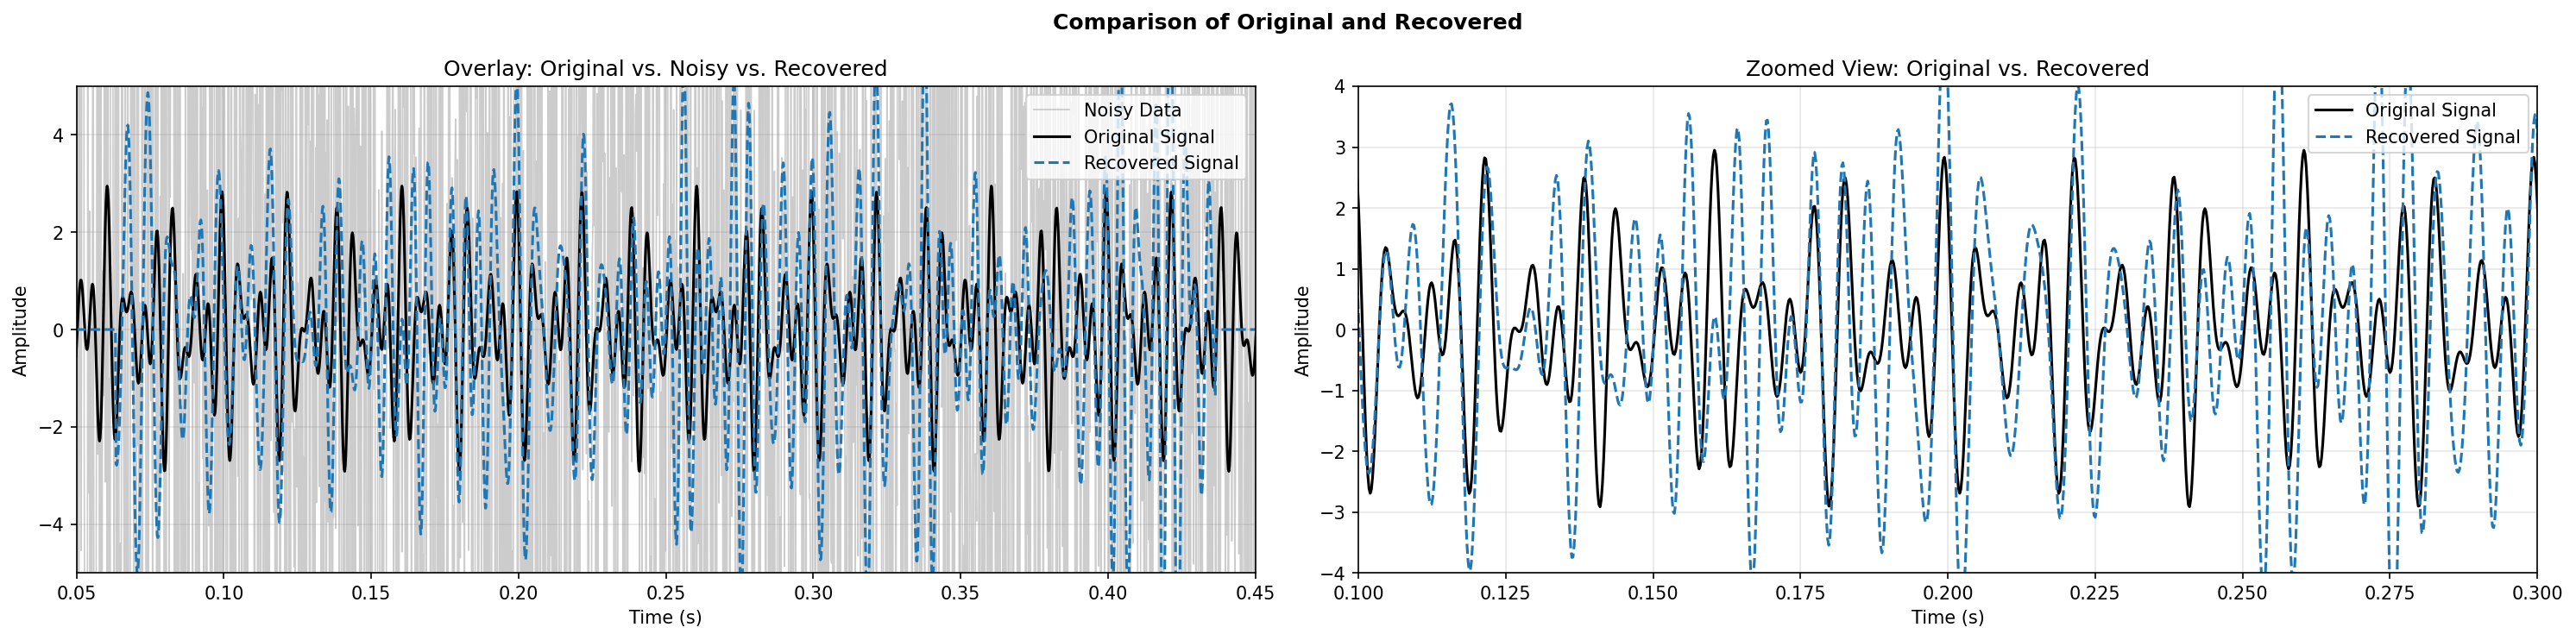

In [15]:
# 7.) Compare the result
fig, axes = plt.subplots(1, 2, figsize=(20, 5), dpi=150)
fig.suptitle('Comparison of Original and Recovered', fontweight='bold')

# all signals across duration
axes[0].plot(t_, noisy_data5, label='Noisy Data', color='gray', alpha=0.4, linewidth=0.8)
axes[0].plot(t_, signal_original, label='Original Signal', color='black', linewidth=1.5)
axes[0].plot(t_, signal_recovered, label='Recovered Signal', color='tab:blue', linestyle='--', linewidth=1.5)
axes[0].set_xlim(0.05, 0.45) # zoom to unwindowed region
axes[0].set_ylim(-5, 5)
axes[0].set_title('Overlay: Original vs. Noisy vs. Recovered')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# direct comparison of original and revcovered plots
axes[1].plot(t_, signal_original, label='Original Signal', color='black', linewidth=1.5)
axes[1].plot(t_, signal_recovered, label='Recovered Signal', color='tab:blue', linestyle='--', linewidth=1.5)
axes[1].set_xlim(0.1, 0.3)  # zoom in to see waveform
axes[1].set_ylim(-4, 4)
axes[1].set_title('Zoomed View: Original vs. Recovered')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("problem2_noiserecover.png")
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

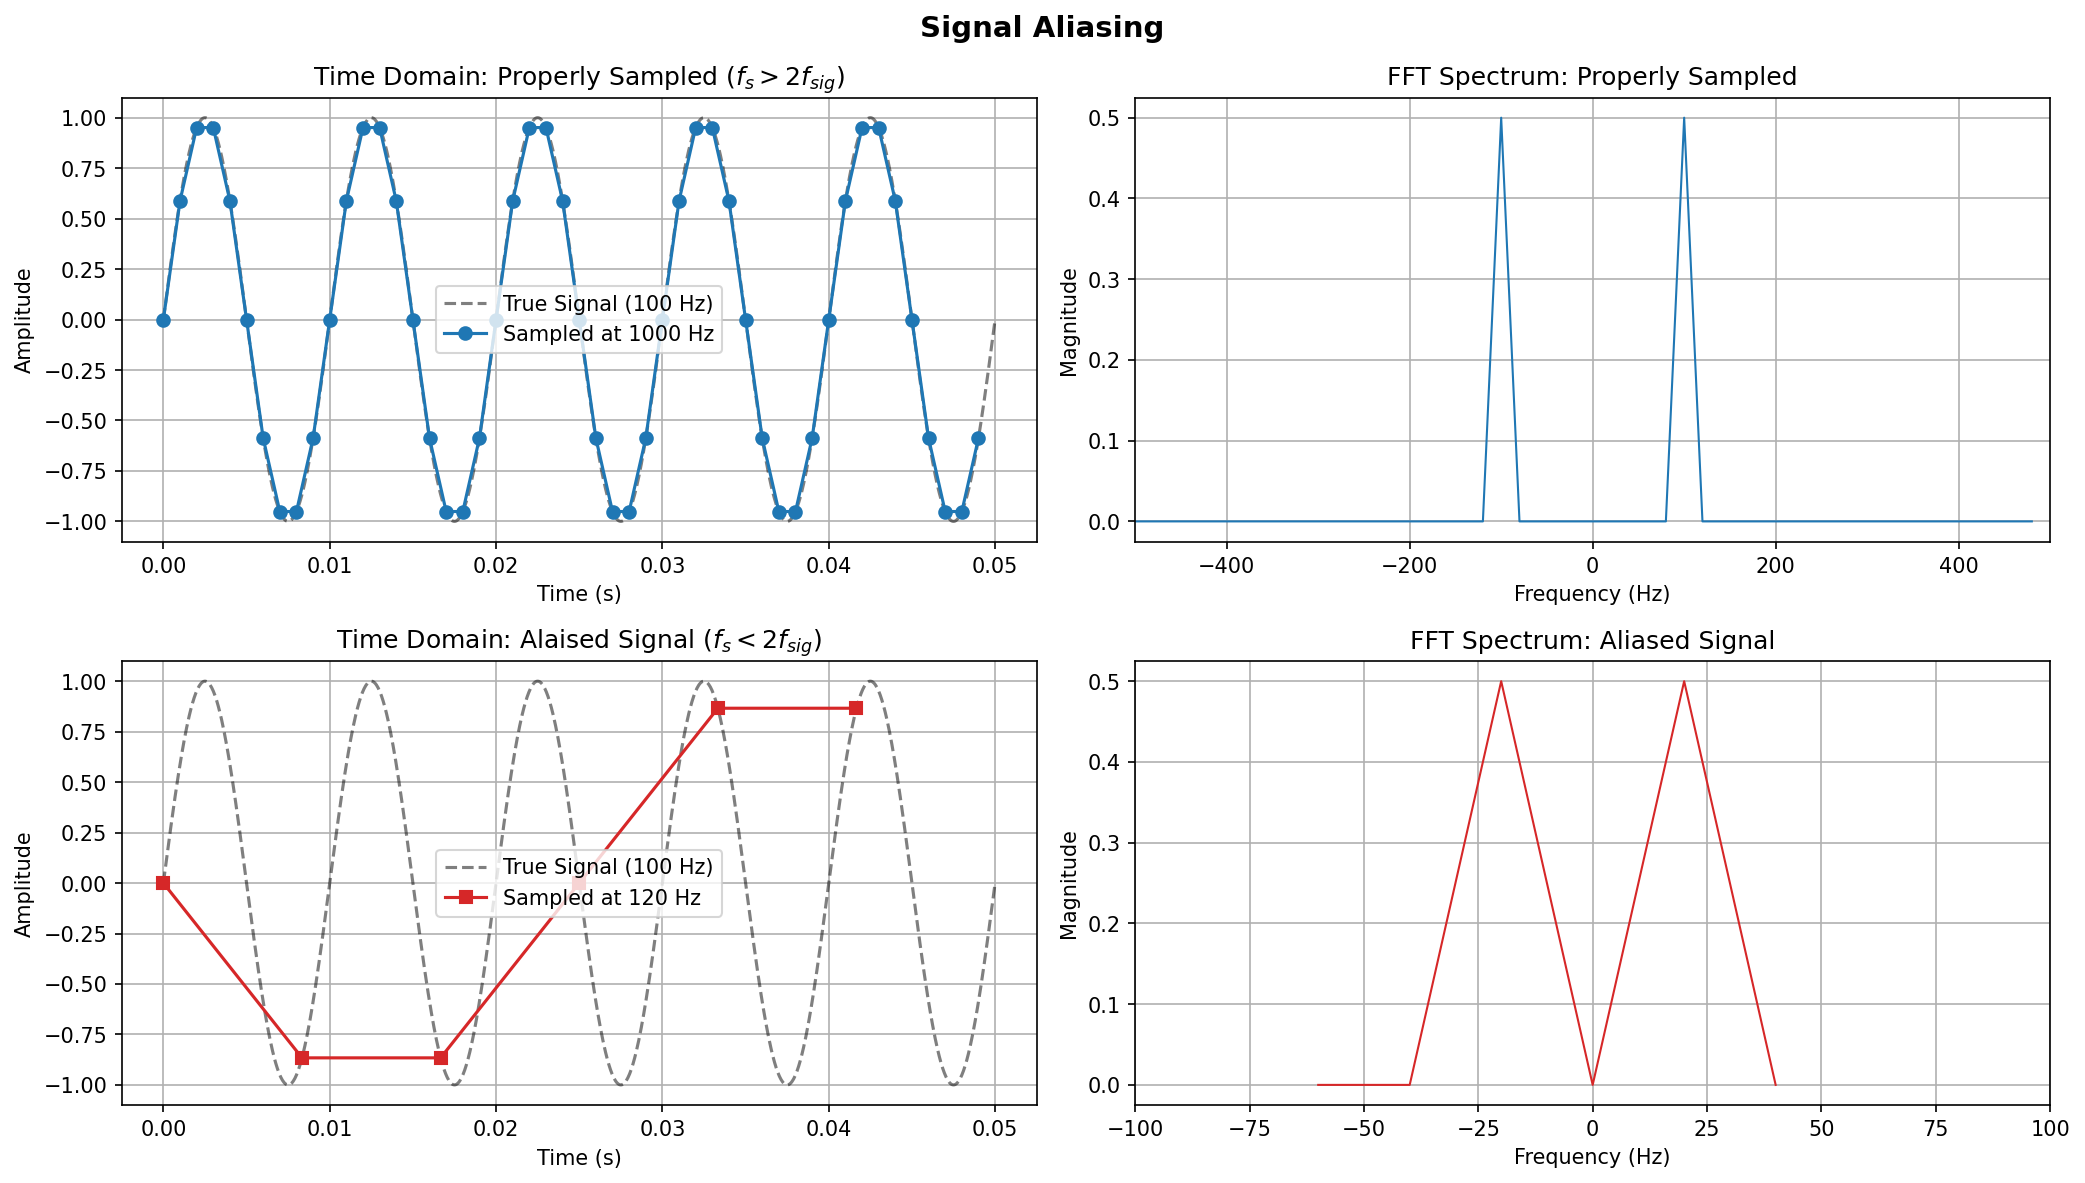

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define Signal Parameters
f_signal = 100  # Signal frequency: 100 Hz
t_end = 0.05    # Duration: 50 ms

# Nyquist Rate is 2 * f_signal = 200 Hz
# Define two sampling rates:
fs_high = 1000  # Above Nyquist (fs > 2 * f_signal) -> Properly sampled
fs_low  = 120   # Below Nyquist (fs < 2 * f_signal) -> Aliased

# Dense time vector for true continuous signal visualization
t_dense = np.linspace(0, t_end, 1000)
signal_true = np.sin(2 * np.pi * f_signal * t_dense)

# signal sampling

# high sampling rate (Properly Sampled)
t_high = np.arange(0, t_end, 1/fs_high)
signal_high = np.sin(2 * np.pi * f_signal * t_high)
N_high = len(signal_high)

# low sampling rate (Aliased)
t_low = np.arange(0, t_end, 1/fs_low)
signal_low = np.sin(2 * np.pi * f_signal * t_low)
N_low = len(signal_low)

# foureir transform area ########################

# Properly Sampled FFT
freqs_high = np.fft.fftshift(np.fft.fftfreq(N_high, d=1/fs_high))
fft_high = np.fft.fftshift(np.abs(np.fft.fft(signal_high))) / N_high

# Aliased FFT
freqs_low = np.fft.fftshift(np.fft.fftfreq(N_low, d=1/fs_low))
fft_low = np.fft.fftshift(np.abs(np.fft.fft(signal_low))) / N_low

# plotting area #############################33

fig, axes = plt.subplots(2, 2, figsize=(14, 8), dpi=150)
fig.suptitle('Signal Aliasing', fontweight='bold', fontsize=14)

# Time Domain Plot (proper sample)
axes[0, 0].plot(t_dense, signal_true, 'k--', alpha=0.5, label='True Signal (100 Hz)')
axes[0, 0].plot(t_high, signal_high, 'o-', color='tab:blue', label=f'Sampled at {fs_high} Hz')
axes[0, 0].set_title('Time Domain: Properly Sampled ($f_s > 2f_{sig}$)')
axes[0, 0].set_xlabel('Time (s)')
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].legend()
axes[0, 0].grid()

# FFT plot (proper sample)
axes[0, 1].plot(freqs_high, fft_high, color='tab:blue', linewidth=1.0)
axes[0, 1].set_title('FFT Spectrum: Properly Sampled')
axes[0, 1].set_xlabel('Frequency (Hz)')
axes[0, 1].set_ylabel('Magnitude')
axes[0, 1].set_xlim(-500, 500)
axes[0, 1].grid()

# Time Domain Plot (Aliased)
axes[1, 0].plot(t_dense, signal_true, 'k--', alpha=0.5, label='True Signal (100 Hz)')
axes[1, 0].plot(t_low, signal_low, 's-', color='tab:red', label=f'Sampled at {fs_low} Hz')
axes[1, 0].set_title('Time Domain: Alaised Signal ($f_s < 2f_{sig}$)')
axes[1, 0].set_xlabel('Time (s)')
axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].legend()
axes[1, 0].grid()

# FFT Plot (Alaiased)
axes[1, 1].plot(freqs_low, fft_low, color='tab:red', linewidth=1.0)
axes[1, 1].set_title('FFT Spectrum: Aliased Signal')
axes[1, 1].set_xlabel('Frequency (Hz)')
axes[1, 1].set_ylabel('Magnitude')
axes[1, 1].set_xlim(-100, 100)
axes[1, 1].grid()

plt.tight_layout()
plt.savefig("problem3_aliasing.png")
plt.show()

#### Problem code summary

In problem 1 the code generated three square pulse sequences of varying lengths and put them into varying FFT methods to show different waveforms. In problem 2 the code took a waveform and introduced random noise, the noisy waveform was then ran through varying methods like introducting a window and FFT methods to attempt to obtain the original lost waveform. In problem 3 the code generated a sinusoidal signal and took the FFT of the above and below Nyquist signal and showed their differences

---
## Section 3: Notes

In [17]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

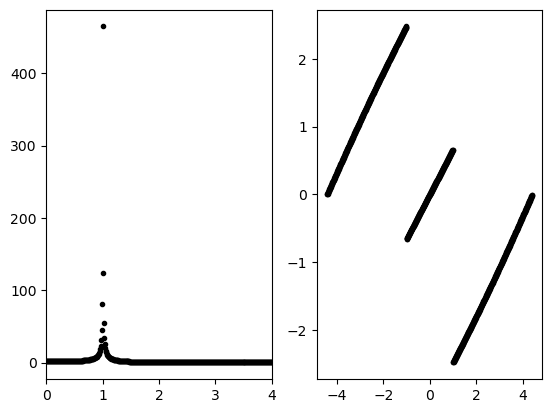

In [18]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [19]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

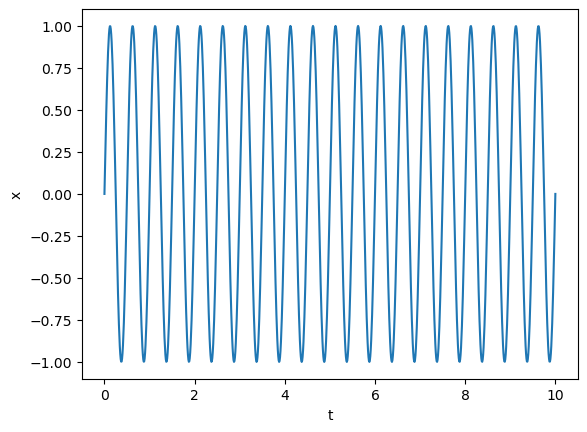

In [20]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [21]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

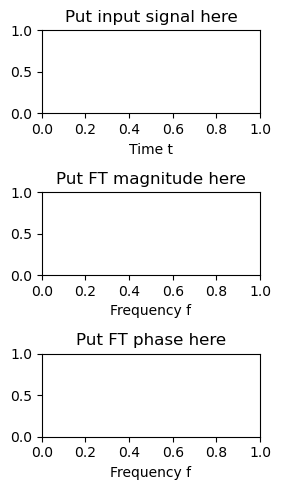

In [22]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

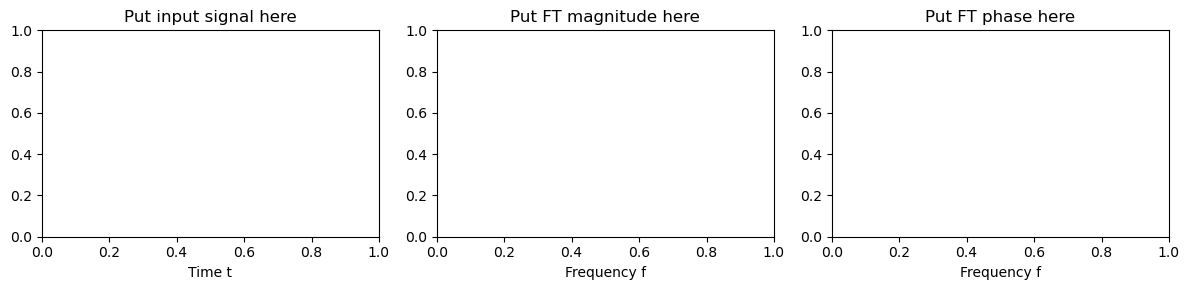

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

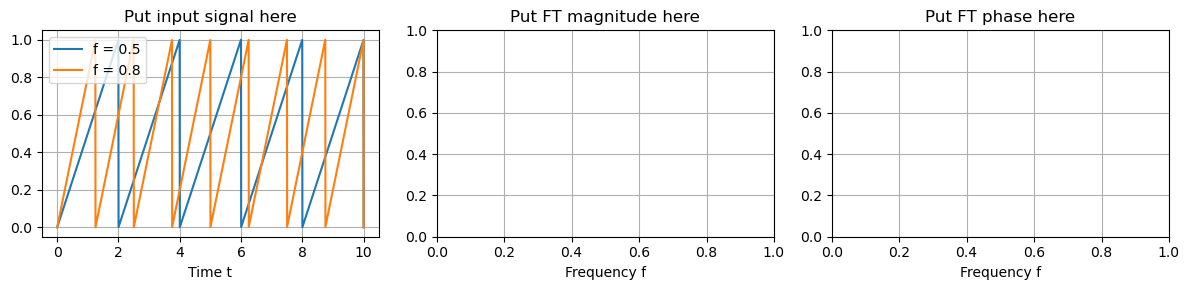

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [25]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



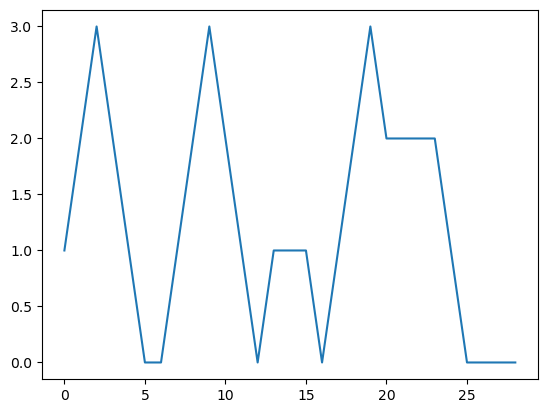

In [26]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [27]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [28]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

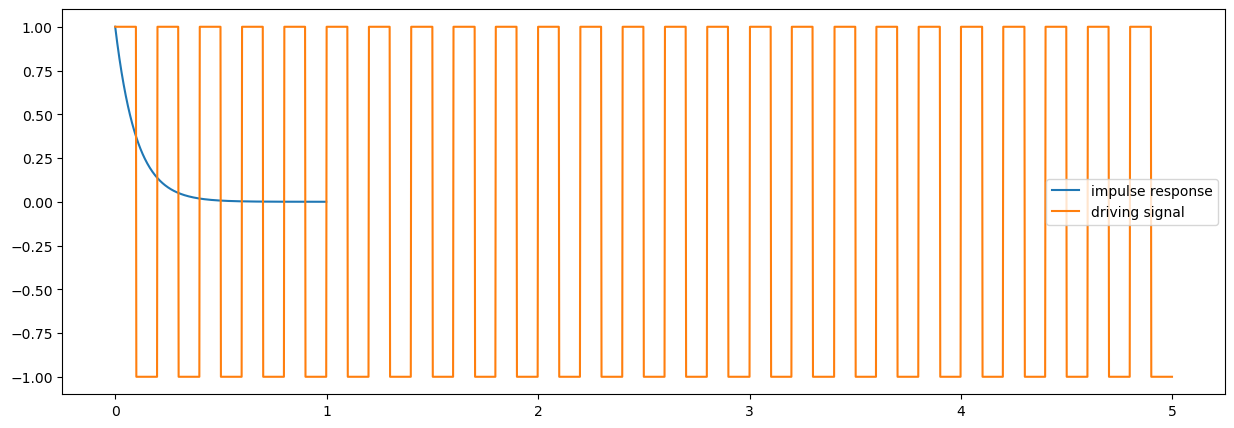

In [29]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [30]:
response = np.convolve(input_signal, h_t, mode = "same")

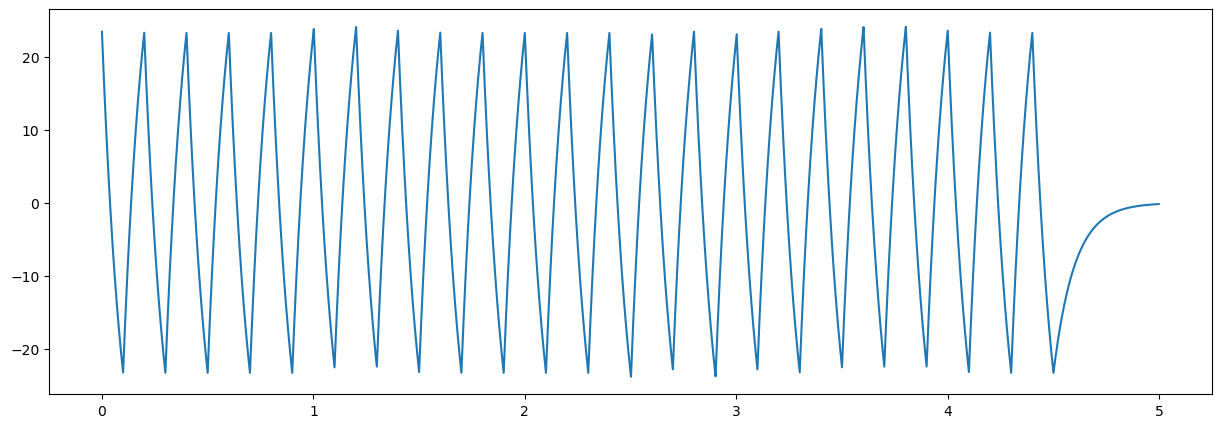

In [31]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [32]:
fourier_length = len(h_t) + len(input_signal) - 1

In [33]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [34]:
fourier_response = fourier_h*fourier_input 

In [35]:
response = np.real(np.fft.ifft(fourier_response))

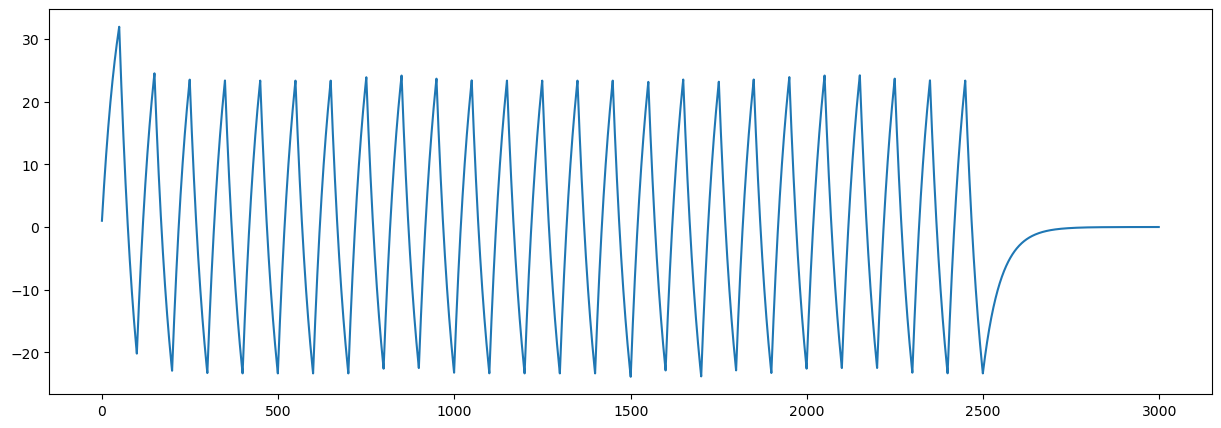

In [36]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)